In [4]:

import sys
from pathlib import Path

from qiskit.quantum_info import Statevector

# Find the project root from the notebook's current directory
current_dir = Path.cwd()

project_root = current_dir

while not (project_root / "src").is_dir():
    if project_root.parent == project_root:
        raise FileNotFoundError(
            "Could not find the project root containing the src folder."
        )
    project_root = project_root.parent

# Add the project root to Python's import path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Python can now search the src folder.")

from src.hash_functions.toy_hash import create_toy_hash_system
from src.classical_attack.preimage_search import classical_preimage_search
from src.quantum_grover.grover_search import create_grover_circuit

print("Imports successful!")


Project root: d:\quantum-project
Python can now search the src folder.
Imports successful!


In [5]:

# Experiment configuration

n_bits = int(input("Enter input bit size (2-8): "))

if not 2 <= n_bits <= 8:
    raise ValueError("Input bit size must be between 2 and 8.")

# For this test, hash size equals input size
m_bits = n_bits

# Create the toy hash map
hash_map = create_toy_hash_system(n_bits, m_bits)

print("\nExperiment created successfully!")
print("Input bits:", n_bits)
print("Hash bits:", m_bits)
print("Total possible inputs:", 2 ** n_bits)
print("Total hash entries:", len(hash_map))



--- Toy Hash System Configuration ---
Input Bit Size (n): 4 (Total inputs: 16)
Hash Output Size (m): 4 bits
-------------------------------------------------------
Input (Binary)   | Input (Dec)  | Hash Output (Binary)
-------------------------------------------------------
|0000>           | 0            | |0000>
|0001>           | 1            | |0001>
|0010>           | 2            | |0010>
|0011>           | 3            | |0011>
|0100>           | 4            | |0100>
|0101>           | 5            | |0101>
|0110>           | 6            | |0110>
|0111>           | 7            | |0111>
|1000>           | 8            | |1000>
|1001>           | 9            | |0011>
|1010>           | 10           | |1010>
|1011>           | 11           | |0001>
|1100>           | 12           | |1100>
|1101>           | 13           | |0111>
|1110>           | 14           | |1110>
|1111>           | 15           | |0101>
-------------------------------------------------------

Experiment 

In [9]:

# Choose a target hash

available_hashes = sorted(set(hash_map.values()))

print("Available hash values:")
print(available_hashes)

target_hash = int(input("\nEnter your target hash: ").strip())

if target_hash not in hash_map.values():
    raise ValueError("Target hash not found. Please choose a listed hash.")

print("\nSelected target hash:", target_hash)


Available hash values:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 14]

Selected target hash: 7


In [10]:
import inspect

print(inspect.signature(classical_preimage_search))
print(inspect.getdoc(classical_preimage_search))

(hash_map, target_hash)
Find every input that produces the target hash.

hash_map: Dictionary containing input -> hash mappings.
target_hash: Integer representation of the target hash.

Returns a list of matching inputs.


In [11]:

# Classical preimage search

classical_matches = classical_preimage_search(hash_map, target_hash)

print("Target hash:", target_hash)
print("Matching inputs:", classical_matches)
print("Number of matching inputs:", len(classical_matches))


Target hash: 7
Matching inputs: [7, 13]
Number of matching inputs: 2


In [12]:

import inspect

print("Function signature:")
print(inspect.signature(create_grover_circuit))

print("\nFunction documentation:")
print(inspect.getdoc(create_grover_circuit))


Function signature:
(hash_map: dict, target_hash, n_bits: int, iterations: int | None = None) -> qiskit.circuit.quantumcircuit.QuantumCircuit

Function documentation:
Build Grover's search circuit using the existing oracle
and the diffusion operator.


Grover circuit created successfully!
Number of qubits: 4
Number of classical bits: 4


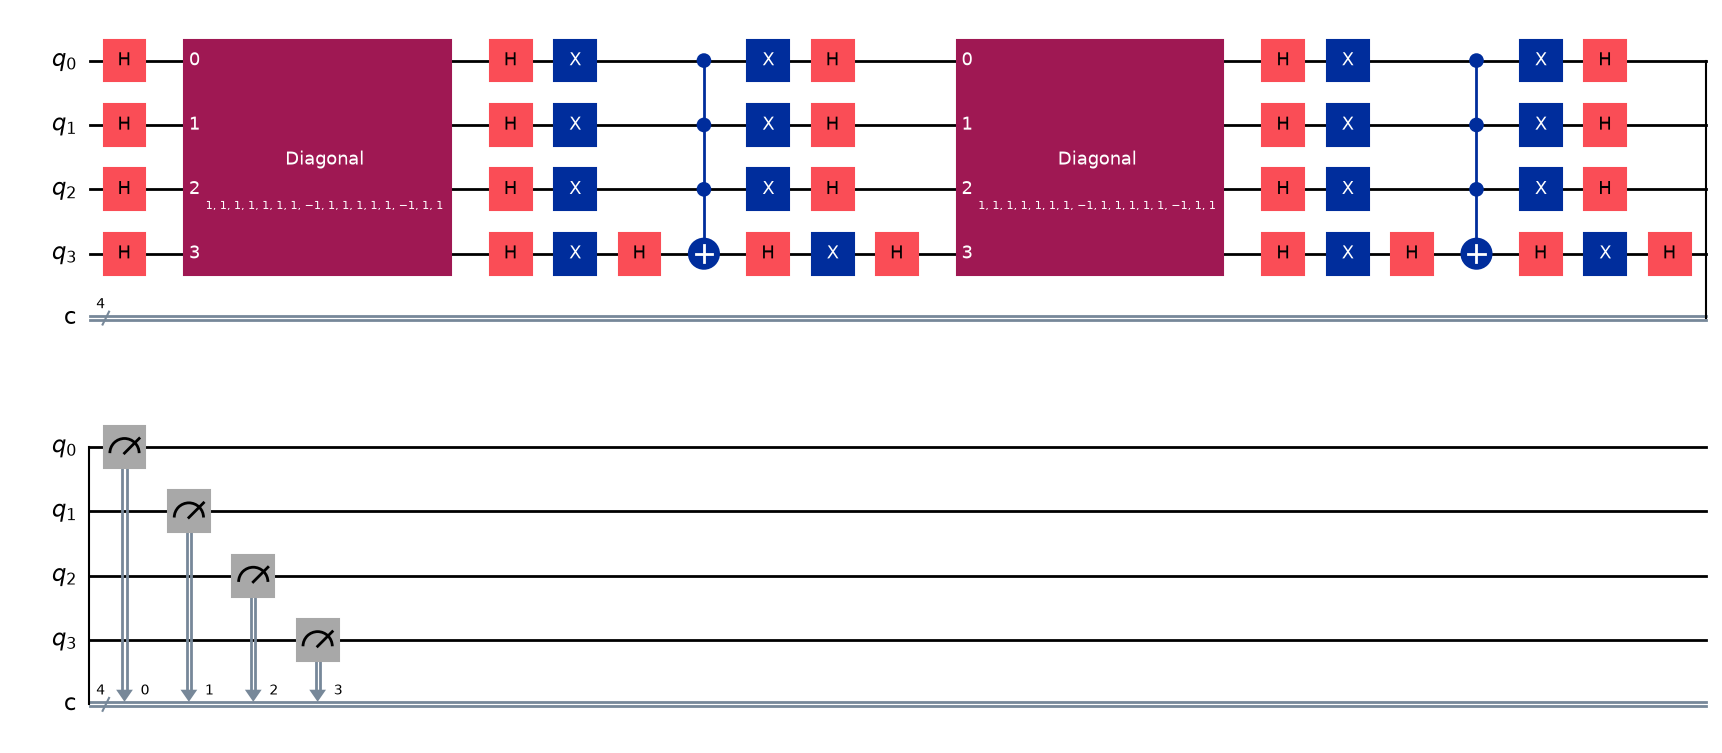

In [13]:

# Build the Grover circuit

grover_circuit = create_grover_circuit(
    hash_map=hash_map,
    target_hash=target_hash,
    n_bits=n_bits
)

print("Grover circuit created successfully!")
print("Number of qubits:", grover_circuit.num_qubits)
print("Number of classical bits:", grover_circuit.num_clbits)

display(grover_circuit.draw(output="mpl"))


In [14]:

# Remove measurements for statevector simulation

unitary_circuit = grover_circuit.remove_final_measurements(inplace=False)

# Simulate the quantum state
state = Statevector.from_instruction(unitary_circuit)

print("Statevector simulation successful!")
print("Number of amplitudes:", len(state.data))


Statevector simulation successful!
Number of amplitudes: 16


In [15]:

# Calculate measurement probability for every input

probabilities = state.probabilities()

print("Input\tProbability")
print("-" * 30)

for input_number, probability in enumerate(probabilities):
    input_bits = format(input_number, f"0{n_bits}b")
    print(f"{input_bits}\t{probability:.6f}")

# Verify total probability
total_probability = sum(probabilities)

print("\nTotal probability:", total_probability)
print("Probability sums to 1:", abs(total_probability - 1.0) < 1e-9)



Input	Probability
------------------------------
0000	0.003906
0001	0.003906
0010	0.003906
0011	0.003906
0100	0.003906
0101	0.003906
0110	0.003906
0111	0.472656
1000	0.003906
1001	0.003906
1010	0.003906
1011	0.003906
1100	0.003906
1101	0.472656
1110	0.003906
1111	0.003906

Total probability: 0.9999999999999938
Probability sums to 1: True


In [16]:

# Compare classical matches with quantum probabilities

print("Target hash:", target_hash)
print("Classical matching inputs:", classical_matches)
print("\nInput | Hash | Classical match? | Quantum probability")
print("-" * 65)

for input_number, probability in enumerate(probabilities):
    input_bits = format(input_number, f"0{n_bits}b")
    hash_value = hash_map[input_number]
    is_match = hash_value == target_hash

    print(
        f"{input_bits} | {hash_value} | "
        f"{is_match} | {probability:.6f}"
    )

matching_probability = sum(
    probabilities[input_number]
    for input_number in range(2 ** n_bits)
    if hash_map[input_number] == target_hash
)

print("\nTotal probability of matching inputs:", matching_probability)
print("Total probability of all inputs:", sum(probabilities))


Target hash: 7
Classical matching inputs: [7, 13]

Input | Hash | Classical match? | Quantum probability
-----------------------------------------------------------------
0000 | 0 | False | 0.003906
0001 | 1 | False | 0.003906
0010 | 2 | False | 0.003906
0011 | 3 | False | 0.003906
0100 | 4 | False | 0.003906
0101 | 5 | False | 0.003906
0110 | 6 | False | 0.003906
0111 | 7 | True | 0.472656
1000 | 8 | False | 0.003906
1001 | 3 | False | 0.003906
1010 | 10 | False | 0.003906
1011 | 1 | False | 0.003906
1100 | 12 | False | 0.003906
1101 | 7 | True | 0.472656
1110 | 14 | False | 0.003906
1111 | 5 | False | 0.003906

Total probability of matching inputs: 0.9453124999999939
Total probability of all inputs: 0.9999999999999938


In [17]:

# Calculate Grover's success probability

total_inputs = 2 ** n_bits

classical_match_count = len(classical_matches)

quantum_success_probability = sum(
    probabilities[i]
    for i in range(total_inputs)
    if hash_map[i] == target_hash
)

initial_success_probability = classical_match_count / total_inputs

print("----- Grover Simulation Summary -----")
print("Input bits:", n_bits)
print("Total possible inputs:", total_inputs)
print("Target hash:", target_hash)
print("Matching inputs:", classical_matches)
print("Number of matching inputs:", classical_match_count)

print(f"\nInitial success probability: {initial_success_probability:.6f}")
print(f"Quantum success probability: {quantum_success_probability:.6f}")

print(
    "Probability amplification factor:",
    f"{quantum_success_probability / initial_success_probability:.2f}x"
)

print(
    "\nTotal probability check:",
    f"{sum(probabilities):.12f}"
)


----- Grover Simulation Summary -----
Input bits: 4
Total possible inputs: 16
Target hash: 7
Matching inputs: [7, 13]
Number of matching inputs: 2

Initial success probability: 0.125000
Quantum success probability: 0.945312
Probability amplification factor: 7.56x

Total probability check: 1.000000000000


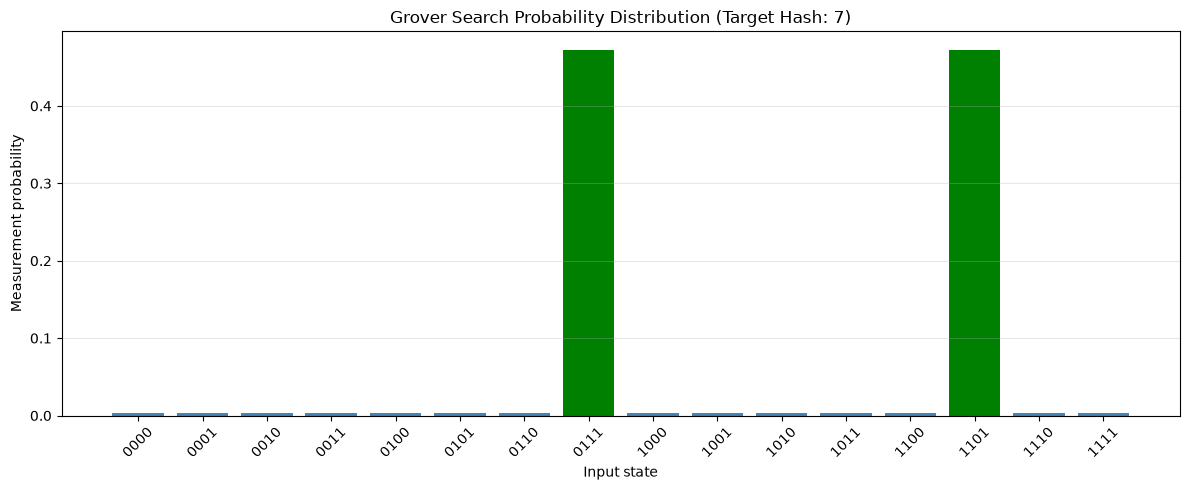

In [18]:

import matplotlib.pyplot as plt

input_labels = [
    format(i, f"0{n_bits}b")
    for i in range(2 ** n_bits)
]

bar_colors = [
    "green" if hash_map[i] == target_hash else "steelblue"
    for i in range(2 ** n_bits)
]

plt.figure(figsize=(12, 5))
plt.bar(input_labels, probabilities, color=bar_colors)

plt.xlabel("Input state")
plt.ylabel("Measurement probability")
plt.title(f"Grover Search Probability Distribution (Target Hash: {target_hash})")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

import csv
from pathlib import Path

# Create the results folder if it doesn't exist
results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

csv_path = results_dir / "grover_simulation_results.csv"

# Save one row for every possible input
with open(csv_path, "w", newline="") as file:
    writer = csv.writer(file)

    writer.writerow([
        "input_decimal",
        "input_binary",
        "hash_value",
        "is_matching_input",
        "quantum_probability"
    ])

    for i, probability in enumerate(probabilities):
        writer.writerow([
            i,
            format(i, f"0{n_bits}b"),
            hash_map[i],
            hash_map[i] == target_hash,
            probability
        ])

print("Results saved successfully!")
print("File location:", csv_path)
print("Total inputs saved:", len(probabilities))


Results saved successfully!
File location: d:\quantum-project\results\grover_simulation_results.csv
Total inputs saved: 16


In [20]:

# Experiment 2: Compare different input sizes

experiment_results = []

for bits in range(2, 9):
    # Create a toy hash system
    experiment_hash_map = create_toy_hash_system(bits, bits)

    # Choose a target that has at least one matching input
    experiment_target = next(iter(experiment_hash_map.values()))

    # Find matching inputs classically
    experiment_matches = classical_preimage_search(
        experiment_hash_map,
        experiment_target
    )

    # Choose an iteration count based on the number of matches
    total_inputs = 2 ** bits
    number_of_matches = len(experiment_matches)

    import math

    if number_of_matches == 0 or number_of_matches == total_inputs:
        iterations = 0
    else:
        theta = math.asin(math.sqrt(number_of_matches / total_inputs))
        iterations = max(0, round(math.pi / (4 * theta) - 0.5))

    # Build the Grover circuit
    experiment_circuit = create_grover_circuit(
        experiment_hash_map,
        experiment_target,
        bits,
        iterations=iterations
    )

    # Simulate the statevector
    experiment_unitary = experiment_circuit.remove_final_measurements(
        inplace=False
    )
    experiment_state = Statevector.from_instruction(experiment_unitary)
    experiment_probabilities = experiment_state.probabilities()

    # Calculate total probability of matching inputs
    success_probability = sum(
        experiment_probabilities[i]
        for i in range(total_inputs)
        if experiment_hash_map[i] == experiment_target
    )

    experiment_results.append({
        "input_bits": bits,
        "total_inputs": total_inputs,
        "matching_inputs": number_of_matches,
        "iterations": iterations,
        "success_probability": success_probability
    })

    print(
        f"{bits} bits | Inputs: {total_inputs:3d} | "
        f"Matches: {number_of_matches:3d} | "
        f"Iterations: {iterations:2d} | "
        f"Success: {success_probability:.4f}"
    )



--- Toy Hash System Configuration ---
Input Bit Size (n): 2 (Total inputs: 4)
Hash Output Size (m): 2 bits
-------------------------------------------------------
Input (Binary)   | Input (Dec)  | Hash Output (Binary)
-------------------------------------------------------
|00>           | 0            | |00>
|01>           | 1            | |01>
|10>           | 2            | |10>
|11>           | 3            | |01>
-------------------------------------------------------
2 bits | Inputs:   4 | Matches:   1 | Iterations:  1 | Success: 1.0000

--- Toy Hash System Configuration ---
Input Bit Size (n): 3 (Total inputs: 8)
Hash Output Size (m): 3 bits
-------------------------------------------------------
Input (Binary)   | Input (Dec)  | Hash Output (Binary)
-------------------------------------------------------
|000>           | 0            | |000>
|001>           | 1            | |001>
|010>           | 2            | |010>
|011>           | 3            | |011>
|100>           | 4

In [21]:

import pandas as pd

# Convert experiment results into a compact table
results_df = pd.DataFrame(experiment_results)

results_df["success_percentage"] = (
    results_df["success_probability"] * 100
)

display(results_df)


,input_bits,total_inputs,matching_inputs,iterations,success_probability,success_percentage
0,2,4,1,1,1.000000,100.000000
1,3,8,1,2,0.945312,94.531250
2,4,16,1,3,0.961319,96.131897
3,5,32,1,4,0.999182,99.918232
4,6,64,1,6,0.996586,99.658568
5,7,128,1,8,0.995620,99.561987
6,8,256,1,12,0.999947,99.994704


In [22]:

# Save the multi-size experiment summary

summary_path = results_dir / "grover_input_size_comparison.csv"

results_df.to_csv(summary_path, index=False)

print("Experiment summary saved successfully!")
print("Saved to:", summary_path)
print("Number of experiments:", len(results_df))


Experiment summary saved successfully!
Saved to: d:\quantum-project\results\grover_input_size_comparison.csv
Number of experiments: 7


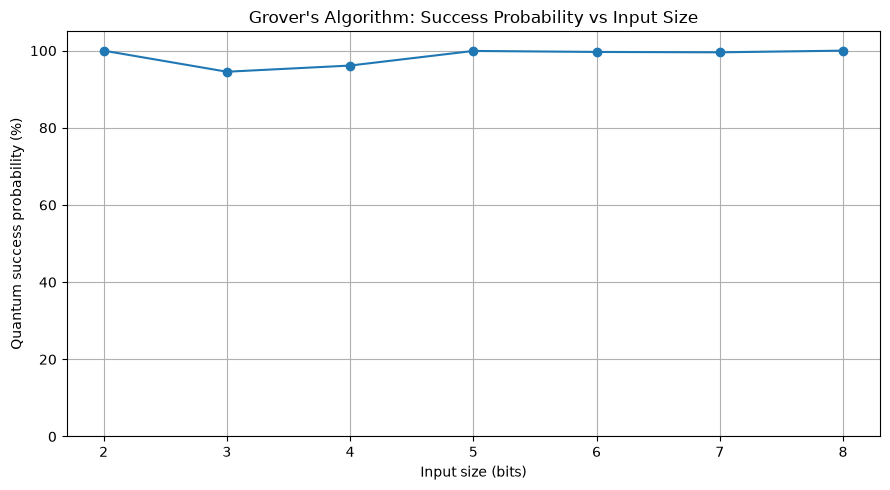

In [23]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["input_bits"],
    results_df["success_probability"] * 100,
    marker="o"
)

plt.xlabel("Input size (bits)")
plt.ylabel("Quantum success probability (%)")
plt.title("Grover's Algorithm: Success Probability vs Input Size")

plt.xticks(results_df["input_bits"])
plt.ylim(0, 105)
plt.grid(True)
plt.tight_layout()
plt.show()


In [24]:

# Save the success-probability graph

graph_path = results_dir / "grover_success_probability.png"

plt.savefig(graph_path, dpi=300, bbox_inches="tight")

print("Graph saved successfully!")
print("Location:", graph_path)


Graph saved successfully!
Location: d:\quantum-project\results\grover_success_probability.png


<Figure size 640x480 with 0 Axes>

In [25]:

# Experiment validation checks

print("----- Experiment Validation -----")

# 1. Check that every input size has a result
assert len(results_df) == 7, "Expected results for input sizes 2 through 8."
assert list(results_df["input_bits"]) == list(range(2, 9))
print("PASS: All input sizes from 2 to 8 are present.")

# 2. Check that probabilities are valid
assert results_df["success_probability"].between(0, 1).all()
print("PASS: Success probabilities are between 0 and 1.")

# 3. Check that every experiment has at least one matching input
assert (results_df["matching_inputs"] > 0).all()
print("PASS: Every experiment has at least one matching input.")

# 4. Check the search-space sizes
assert (
    results_df["total_inputs"] == 2 ** results_df["input_bits"]
).all()
print("PASS: Search-space sizes are correct.")

# 5. Check the current statevector probabilities
assert abs(sum(probabilities) - 1.0) < 1e-9
print("PASS: Current statevector probabilities sum to 1.")

print("\nAll validation checks passed!")


----- Experiment Validation -----
PASS: All input sizes from 2 to 8 are present.
PASS: Success probabilities are between 0 and 1.
PASS: Every experiment has at least one matching input.
PASS: Search-space sizes are correct.
PASS: Current statevector probabilities sum to 1.

All validation checks passed!


In [26]:

# Correctness Check 1: Compare classical matches with oracle matches

from qiskit.quantum_info import Statevector
import numpy as np

# Build the oracle using the existing function
from src.quantum_grover.oracle import create_grover_oracle

oracle = create_grover_oracle(
    hash_map,
    target_hash,
    n_bits
)

# Simulate the oracle acting on every possible basis state
oracle_state = Statevector.from_int(0, 2**n_bits)

# Test each input independently
oracle_matches = []

for input_number in range(2**n_bits):
    basis_state = Statevector.from_int(input_number, 2**n_bits)
    result = basis_state.evolve(oracle)

    # A correctly marked state gets amplitude -1
    amplitude = result.data[input_number]

    if np.isclose(amplitude, -1.0):
        oracle_matches.append(input_number)
    elif not np.isclose(amplitude, 1.0):
        print("Unexpected amplitude for input:", input_number)

print("Classical matching inputs:", sorted(classical_matches))
print("Oracle-marked inputs:", sorted(oracle_matches))

if sorted(classical_matches) == sorted(oracle_matches):
    print("PASS: Oracle marks exactly the classical matching inputs.")
else:
    print("FAIL: Classical matches and oracle markings differ.")


Classical matching inputs: [7, 13]
Oracle-marked inputs: [7, 13]
PASS: Oracle marks exactly the classical matching inputs.


In [27]:

# Correctness Check 2: Verify diffusion operator

import numpy as np
from qiskit.quantum_info import Operator

from src.quantum_grover.grover_search import create_diffusion_operator

diffusion = create_diffusion_operator(n_bits)
diffusion_matrix = Operator(diffusion).data

identity = np.eye(2 ** n_bits)

is_unitary = np.allclose(
    diffusion_matrix.conj().T @ diffusion_matrix,
    identity
)

print("Number of qubits:", n_bits)
print("Diffusion matrix shape:", diffusion_matrix.shape)
print("Unitary:", is_unitary)

assert is_unitary, "Diffusion operator failed the unitary check."

print("PASS: Diffusion operator is unitary.")


Number of qubits: 4
Diffusion matrix shape: (16, 16)
Unitary: True
PASS: Diffusion operator is unitary.


In [28]:

# Correctness Check 3: Compare simulation with theory

import math
import numpy as np

N = 2 ** n_bits
M = len(classical_matches)

# Use the iteration count from the existing Grover circuit
# The circuit builder's default is used here, so inspect its
# source to confirm the actual iteration count before comparing.
import inspect

print(inspect.getsource(create_grover_circuit))


def create_grover_circuit(
    hash_map: dict,
    target_hash,
    n_bits: int,
    iterations: int | None = None,
) -> QuantumCircuit:
    """
    Build Grover's search circuit using the existing oracle
    and the diffusion operator.
    """

    if not 1 <= n_bits <= 8:
        raise ValueError("n_bits must be between 1 and 8.")

    # Find the inputs whose hashes match the target.
    marked_inputs = find_marked_inputs(hash_map, target_hash)

    if not marked_inputs:
        raise ValueError("No input produces the target hash.")

    total_inputs = 2**n_bits
    number_marked = len(marked_inputs)

    if number_marked > total_inputs:
        raise ValueError("Invalid number of matching inputs.")

    # Choose a reasonable iteration count automatically.
    if iterations is None:
        if number_marked == total_inputs:
            iterations = 0
        else:
            angle = math.asin(math.sqrt(number_marked / total_inputs))
            iterations = max(
                0,
 

In [29]:

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Create a circuit with one qubit
qc = QuantumCircuit(1)

# Add a Hadamard gate
qc.h(0)

# Display the circuit
print(qc.draw())

# Simulate the circuit
state = Statevector.from_instruction(qc)

print("Statevector:", state.data)
print("Probabilities:", state.probabilities())


   ┌───┐
q: ┤ H ├
   └───┘
Statevector: [0.70710678+0.j 0.70710678+0.j]
Probabilities: [0.5 0.5]


In [30]:

import numpy as np
from qiskit.quantum_info import Operator

from src.quantum_grover.grover_search import create_diffusion_operator

# Create the diffusion operator for the current input size
diffusion = create_diffusion_operator(n_bits)

# Convert the circuit into a matrix
diffusion_matrix = Operator(diffusion).data

# A unitary operator must satisfy U†U = I
identity = np.eye(2 ** n_bits)

is_unitary = np.allclose(
    diffusion_matrix.conj().T @ diffusion_matrix,
    identity
)

print("Number of qubits:", n_bits)
print("Diffusion matrix shape:", diffusion_matrix.shape)
print("Is diffusion operator unitary?", is_unitary)

assert is_unitary, "FAIL: Diffusion operator is not unitary!"

print("PASS: Diffusion operator is unitary.")


Number of qubits: 4
Diffusion matrix shape: (16, 16)
Is diffusion operator unitary? True
PASS: Diffusion operator is unitary.


In [31]:

import math
import numpy as np

# Use the existing experiment's values
N = 2 ** n_bits
M = len(classical_matches)

# Read the actual iteration count from the circuit function's default
# For this check, use the circuit already simulated.
actual_circuit = create_grover_circuit(
    hash_map,
    target_hash,
    n_bits
)

# Remove measurements before statevector simulation
circuit_without_measurements = (
    actual_circuit.remove_final_measurements(inplace=False)
)

state_check = Statevector.from_instruction(
    circuit_without_measurements
)

# Calculate the measured success probability
actual_probabilities = state_check.probabilities()

actual_success = sum(
    actual_probabilities[i]
    for i in range(N)
    if hash_map[i] == target_hash
)

# Determine how many Grover iterations were actually applied
print("Circuit operations:")
print(actual_circuit.count_ops())

print("\nNumber of possible inputs:", N)
print("Number of matching inputs:", M)
print("Actual success probability:", actual_success)

# Infer Grover iterations from the circuit's operation count
# We'll inspect the circuit structure before asserting correctness.
print("\nCircuit qubit count:", actual_circuit.num_qubits)
print("Circuit classical bit count:", actual_circuit.num_clbits)


Circuit operations:
OrderedDict({'h': 24, 'x': 16, 'measure': 4, 'diagonal': 2, 'mcx': 2})

Number of possible inputs: 16
Number of matching inputs: 2
Actual success probability: 0.9453124999999939

Circuit qubit count: 4
Circuit classical bit count: 4


In [33]:

# Correctness Check 4: Test different Grover iteration counts

iteration_results = []

for iterations in range(5):
    test_circuit = create_grover_circuit(
        hash_map=hash_map,
        target_hash=target_hash,
        n_bits=n_bits,
        iterations=iterations
    )

    test_circuit = test_circuit.remove_final_measurements(
        inplace=False
    )

    test_state = Statevector.from_instruction(test_circuit)
    test_probabilities = test_state.probabilities()

    success_probability = sum(
        test_probabilities[i]
        for i in range(2 ** n_bits)
        if hash_map[i] == target_hash
    )

    iteration_results.append((iterations, success_probability))

print("Grover iterations | Success probability")
print("-" * 40)

for iterations, probability in iteration_results:
    print(f"{iterations:17d} | {probability:.6f}")


Grover iterations | Success probability
----------------------------------------
                0 | 0.125000
                1 | 0.781250
                2 | 0.945312
                3 | 0.330078
                4 | 0.012207


In [35]:

import math
from qiskit.quantum_info import Statevector

# Configuration: change these values to experiment
n_bits = 4
matching_counts = [1, 2, 4]

target_hash = "TARGET"
other_hash = "OTHER"

N = 2 ** n_bits

print(f"Total possible inputs: {N}")
print("=" * 60)

for M in matching_counts:

    # Create a test hash map with exactly M matching inputs
    hash_map = {
        input_value: target_hash if input_value < M else other_hash
        for input_value in range(N)
    }

    # Let our function choose the iteration count automatically
    auto_circuit = create_grover_circuit(
        hash_map=hash_map,
        target_hash=target_hash,
        n_bits=n_bits
    )

    # Remove measurements to calculate statevector probabilities
    auto_unitary_circuit = auto_circuit.remove_final_measurements(
        inplace=False
    )
    auto_state = Statevector.from_instruction(auto_unitary_circuit)

    # Success probability = total probability of all matching inputs
    auto_success = sum(
        abs(auto_state.data[i]) ** 2
        for i in range(M)
    )

    # Theoretical estimate used by the implementation
    if M == N:
        theoretical_iterations = 0
    else:
        angle = math.asin(math.sqrt(M / N))
        theoretical_iterations = max(
            0,
            round(math.pi / (4 * angle) - 0.5)
        )

    # Test manually selected iteration counts for comparison
    results = []

    for iterations in range(0, 6):
        test_circuit = create_grover_circuit(
            hash_map=hash_map,
            target_hash=target_hash,
            n_bits=n_bits,
            iterations=iterations
        )

        test_circuit = test_circuit.remove_final_measurements(
            inplace=False
        )
        test_state = Statevector.from_instruction(test_circuit)

        success = sum(
            abs(test_state.data[i]) ** 2
            for i in range(M)
        )

        results.append((iterations, success))

    best_iterations, best_probability = max(
        results, key=lambda result: result[1]
    )

    print(f"\nMatching inputs (M): {M}")
    print(f"Automatic success probability: {auto_success:.6f}")
    print(
        "Success probability at theoretical estimate: "
        f"{results[theoretical_iterations][1]:.6f}"
    )
    print(
        f"Best tested iteration count: {best_iterations}"
    )
    print(
        f"Best tested success probability: {best_probability:.6f}"
    )
    print("Manual iteration results:")

    for iterations, probability in results:
        print(f"  {iterations} iterations: {probability:.6f}")

    print("-" * 60)


Total possible inputs: 16

Matching inputs (M): 1
Automatic success probability: 0.961319
Success probability at theoretical estimate: 0.961319
Best tested iteration count: 3
Best tested success probability: 0.961319
Manual iteration results:
  0 iterations: 0.062500
  1 iterations: 0.472656
  2 iterations: 0.908447
  3 iterations: 0.961319
  4 iterations: 0.581704
  5 iterations: 0.125492
------------------------------------------------------------

Matching inputs (M): 2
Automatic success probability: 0.945312
Success probability at theoretical estimate: 0.945312
Best tested iteration count: 2
Best tested success probability: 0.945312
Manual iteration results:
  0 iterations: 0.125000
  1 iterations: 0.781250
  2 iterations: 0.945312
  3 iterations: 0.330078
  4 iterations: 0.012207
  5 iterations: 0.547974
------------------------------------------------------------

Matching inputs (M): 4
Automatic success probability: 1.000000
Success probability at theoretical estimate: 1.000000


In [40]:

from qiskit.quantum_info import Statevector

# 1. Get user input
n_bits = int(input("Enter input size in bits (1-8): "))
N = 2 ** n_bits

M = int(input(f"Enter number of matching inputs (1-{N}): "))

# 2. Validate input
if not 1 <= n_bits <= 8:
    raise ValueError("Input bits must be between 1 and 8.")

if not 1 <= M <= N:
    raise ValueError(f"Matching inputs must be between 1 and {N}.")

target_hash = "TARGET"
other_hash = "OTHER"

# 3. Create a test hash map with M matching inputs
hash_map = {
    value: target_hash if value < M else other_hash
    for value in range(N)
}

# 4. Let the function choose iterations automatically
auto_circuit = create_grover_circuit(
    hash_map=hash_map,
    target_hash=target_hash,
    n_bits=n_bits
)

# Count the iterations used by the circuit
auto_iterations = sum(
    1 for instruction in auto_circuit.data
    if instruction.operation.name == "circuit-?"
)

print(f"\nTotal possible inputs: {N}")
print(f"Matching inputs: {M}")
print("Automatic circuit created successfully!")

# 5. Test iteration counts manually
results = []

for r in range(6):
    circuit = create_grover_circuit(
        hash_map=hash_map,
        target_hash=target_hash,
        n_bits=n_bits,
        iterations=r
    )

    circuit.remove_final_measurements(inplace=True)
    state = Statevector.from_instruction(circuit)

    probability = sum(
        abs(state.data[i]) ** 2
        for i in range(M)
    )

    results.append((r, probability))

print("\nSuccess probability for each iteration:")
for r, probability in results:
    print(f"{r} iterations: {probability:.6f}")

best_r, best_p = max(results, key=lambda item: item[1])

print(f"\nBest tested iteration count: {best_r}")
print(f"Best success probability: {best_p:.6f}")



Total possible inputs: 16
Matching inputs: 4
Automatic circuit created successfully!

Success probability for each iteration:
0 iterations: 0.250000
1 iterations: 1.000000
2 iterations: 0.250000
3 iterations: 0.250000
4 iterations: 1.000000
5 iterations: 0.250000

Best tested iteration count: 1
Best success probability: 1.000000


In [43]:

import math
from qiskit.quantum_info import Statevector

# 1. User configuration
n_bits = int(input("Enter input size in bits (1-8): "))
N = 2 ** n_bits

if not 1 <= n_bits <= 8:
    raise ValueError("Input size must be between 1 and 8.")

M = int(input(f"Enter matching inputs (1-{N}): "))

if not 1 <= M <= N:
    raise ValueError(f"Matching inputs must be between 1 and {N}.")

target_hash = "TARGET"
other_hash = "OTHER"

# 2. Create a test hash map with exactly M matches
hash_map = {
    value: target_hash if value < M else other_hash
    for value in range(N)
}

# 3. Create the automatically configured circuit
auto_circuit = create_grover_circuit(
    hash_map=hash_map,
    target_hash=target_hash,
    n_bits=n_bits
)

auto_circuit.remove_final_measurements(inplace=True)
auto_state = Statevector.from_instruction(auto_circuit)

# 4. Calculate the theoretical iteration estimate
if M == N:
    theoretical_iterations = 0
else:
    angle = math.asin(math.sqrt(M / N))
    theoretical_iterations = max(
        0,
        round(math.pi / (4 * angle) - 0.5)
    )

# 5. Compare the automatic state with manually configured circuits
matching_iterations = []

for r in range(0, 2 * N + 1):
    manual_circuit = create_grover_circuit(
        hash_map=hash_map,
        target_hash=target_hash,
        n_bits=n_bits,
        iterations=r
    )

    manual_circuit.remove_final_measurements(inplace=True)
    manual_state = Statevector.from_instruction(manual_circuit)

    # Compare the complete quantum states, allowing global phase
    if auto_state.equiv(manual_state):
        matching_iterations.append(r)

# 6. Display the results
print("\n--- AUTOMATIC ITERATION VERIFICATION ---")
print(f"Input bits: {n_bits}")
print(f"Total possible inputs: {N}")
print(f"Matching inputs: {M}")
print(f"Theoretical iteration estimate: {theoretical_iterations}")
print(f"Matching manual iteration counts: {matching_iterations}")

if theoretical_iterations in matching_iterations:
    print("PASS: Automatic circuit matches the theoretical estimate.")
else:
    print("CHECK: Automatic circuit differs from the theoretical estimate.")



--- AUTOMATIC ITERATION VERIFICATION ---
Input bits: 4
Total possible inputs: 16
Matching inputs: 4
Theoretical iteration estimate: 1
Matching manual iteration counts: [1, 4, 7, 10, 13, 16, 19, 22, 25, 28, 31]
PASS: Automatic circuit matches the theoretical estimate.
